# NEST-SOC-EIS: tutorial

Build a solid oxide cell, solve a steady operating point, apply voltage-ramp, current-interrupt, and impedance simulations.

## 1. Import the required classes

NEST-SOC (`nest`) provides material and cell definitions; NEST-SOC-EIS (`nesteis`) provides the distributed model, solvers, protocols, and plotting.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import SVG, display
from nest.boundary import BoundaryData
from nest.cell import Cell
from nest.constants import R
from nest.layers import ButlerVolmer, Conductivity, Layer, PorousTransport
from nest.properties import BasicSpecies, Mixture
from nesteis import (
    CellEIS, ChannelGeometry, ElectrodeEIS, Model,
    solve_steady, solve_transient, voltage_ramp, current_interrupt,
    impedance, plot_impedance, plot_transient, save_results,
)

## 2. Defining the cell

### 2.1. Porous media

In [3]:
# dp: mean pore diameter [m]; epsilon: gas porosity [-]; tau: gas tortuosity [-].
fuel_transport = PorousTransport(dp=600e-9, epsilon=0.30, tau=2.5)
air_transport = PorousTransport(dp=600e-9, epsilon=0.30, tau=2.5)
support_transport = PorousTransport(dp=600e-9, epsilon=0.30, tau=2.5)


### 2.2. Fuel and air electrodes

In [4]:
# Effective electrode ionic conductivity includes ionic-phase fraction/tortuosity.
# sigma(T) = sigma0 * T**theta * exp(-E_act/(R*T)); sigma0 is the conductivity prefactor.
# Exchange current per TPB length uses i0 = A_r*T**theta*exp(-Ea/RT)*pressure_factor.
# A_r is supplied later in ElectrodeEIS; kinetic.gamma from nest is not used by this model.
fuel_ionic_fraction = 0.58 * (1.0 - fuel_transport.epsilon)  # Fraction of total electrode volume [-].
fuel_ionic_tortuosity = 2.8  # Ionic tortuosity [-], distinct from gas tortuosity.

fuel = Layer(
    delta=10e-6,        # Fuel-electrode thickness [m].
    transport=fuel_transport,
    kinetic=ButlerVolmer(
        gas=Mixture((BasicSpecies.H2, BasicSpecies.H2O)),  # Species order for nu and p.
        nu=[-1.0, 1.0],         # H2 consumed; H2O produced (fuel-cell direction) [-].
        n_e=2,                  # Electrons transferred per half-reaction [-].
        alpha=0.59,             # Forward charge-transfer coefficient [-].
        beta=0.41,              # Reverse charge-transfer coefficient [-].
        p=[-0.10, 0.33],        # H2 and H2O exponents for exchange current [-].
        theta=1,                # Temperature exponent for exchange current [-].
        E_act=160e3,           # Reaction activation energy [J/mol].
    ),
    conductivity=Conductivity(
        sigma0=3.6e7 * fuel_ionic_fraction / fuel_ionic_tortuosity,  # Effective conductivity prefactor.
        E_act=80e3,             # Ionic-conduction activation energy [J/mol].
        theta=-1,               # Temperature exponent for ionic conductivity [-].
    ),
)

# Air-electrode ionic fraction can differ from the fuel-electrode value.
air_ionic_fraction = 0.50 * (1.0 - air_transport.epsilon)  # Fraction of total volume [-].
air_ionic_tortuosity = 1.8  # Ionic-phase tortuosity [-].

air = Layer(
    delta=30e-6,        # Air-electrode thickness [m].
    transport=air_transport,
    kinetic=ButlerVolmer(
        gas=Mixture((BasicSpecies.O2, BasicSpecies.N2)),  # Species order for nu and p.
        nu=[-0.5, 0.0],         # O2 consumed; N2 inert (fuel-cell direction) [-].
        n_e=2,                  # Electrons transferred per half-reaction [-].
        alpha=0.65,             # Forward charge-transfer coefficient [-].
        beta=0.35,              # Reverse charge-transfer coefficient [-].
        p=[0.22, 0.0],          # O2 and N2 exponents for exchange current [-].
        theta=1,                # Temperature exponent for exchange current [-].
        E_act=150e3,           # Reaction activation energy [J/mol].
    ),
    conductivity=Conductivity(
        sigma0=1.1e7 * air_ionic_fraction / air_ionic_tortuosity,  # Effective conductivity prefactor.
        E_act=62e3,          # Ionic-conduction activation energy [J/mol].
        theta=-1,               # Temperature exponent for ionic conductivity [-].
    ),
)


### 2.3. Electrolyte layers

In [5]:
# Each electrolyte-like layer contributes an ohmic resistance delta / sigma(T).
# Conductivity(T) = sigma0 * T**theta * exp(-E_act / (R*T)).
electrolyte = (
    Layer(
        delta=12e-6,  # YSZ thickness [m].
        conductivity=Conductivity(sigma0=3.6e7, E_act=80e3, theta=-1),
    ),
    Layer(
        delta=8e-6,   # CGO thickness [m].
        conductivity=Conductivity(sigma0=1.1e7, E_act=62e3, theta=-1),
    ),
    Layer(
        delta=1e-6,   # CGO/YSZ interdiffusion-layer thickness [m].
        conductivity=Conductivity(sigma0=0.23, E_act=67e3, theta=1),
    ),
)

### 2.4. Cell definition

In [6]:
# Active electrochemical area [m²]; independent of channel cross-section.
cell = Cell(
    area=0.04 * 0.04,
    electrode_fuel=fuel,
    electrode_air=air,
    electrolyte=electrolyte,
)

### 2.5. EIS parameters

`CellEIS` complements the material and layer definitions from `nest` with inputs needed for impedance calculations, which include:
1. Electrode reaction and capacitance parameters 
2. **Channel geometries** and **fuel support** as their gas transport and storage affect the transient response (support has no electrochemical reaction).

In [7]:
# Rounded example values; capacitance is given per electrode volume [F/m³].
cell_eis = CellEIS(
    fuel=ElectrodeEIS(
        tpb_density=3.1e12,          # TPB length per electrode volume [m^-2].
        exchange_current_prefactor=60.0,  # A_r [A/(m K^theta)], TPB-based kinetics.
        capacitance_volumetric=1.4e6,  # [F/m³].
    ),
    air=ElectrodeEIS(
        tpb_density=3.5e12,          # TPB length per electrode volume [m^-2].
        exchange_current_prefactor=10.0,  # A_r [A/(m K^theta)], TPB-based kinetics.
        capacitance_volumetric=7.6e7,  # [F/m³].
    ),
    # Channel length along the flow, width across flow, thickness = gas-channel height [m].
    fuel_channel=ChannelGeometry(length=0.04, width=0.04, thickness=1e-3),
    air_channel=ChannelGeometry(length=0.04, width=0.04, thickness=1e-3),
    support_thickness=300e-6,  # Fuel support thickness [m]; explicitly meshed.
    support_transport=support_transport,  # Support has gas storage/transport, no reaction.
    fuel_pressure=101325.0,   # Fuel-side absolute pressure [Pa].
    air_pressure=101325.0,    # Air-side absolute pressure [Pa].
)

### 2.6. Operating conditions and numerical grid

In [8]:
# Inlet flows are specified as litres/hour at 273.15 K and 1 bar.
# Conversion factor: (L/h) -> (m³/s) -> (mol/s), using the ideal gas law.
flow_factor = 1e5 * 1e-3 / (3600 * R * 273.15)  # [mol/s per (L/h)].

boundary = BoundaryData(
    T=807 + 273.15,               # Isothermal operating temperature [K].
    P=101325.0,                  # Boundary reference pressure [Pa].
    n_fuel=flow_factor * 24.0 * np.array([0.50, 0.50]),  # H2/H2O molar inlet flows [mol/s].
    n_air=flow_factor * 50.0 * np.array([0.21, 0.79]),   # O2/N2 molar inlet flows [mol/s].
)

# Number of channel, fuel, air and support control volumes, respectively.
# This small grid is for demonstration; increase it for mesh-convergence studies.
model = Model(cell, cell_eis, boundary, n_x=10, n_zf=4, n_za=3, n_zs=2)

## 3. Steady-state simulation

 **50 mV above the initial OCV**. Both voltage ramp and current interrupt start from this steady state: 
 1. Voltage ramps down to OCV
 2. Current interrupts to zero

In [9]:
# Initial zero-mean-current voltage estimate, based on inlet composition [V].
ocv = model.voltage_for_current(model.initial_state())
voltage_before = ocv + 50e-3  # Imposed pre-excitation voltage [V].

steady = solve_steady(model, voltage_before)  # Solve the stationary state once.
current_profile = model.current_density(steady.x, voltage_before)  # j(x) [A/m²].
current_before = float(current_profile.mean())  # Mean cell current density [A/m²].
eta_fuel, eta_air = model.overpotentials(steady.x)  # eta(z, x) [V].

print(f"OCV estimate:           {ocv:.6f} V")
print(f"Steady voltage:        {voltage_before:.6f} V")
print(f"Mean current density:  {current_before:.4f} A/m²")
print(f"Maximum scaled error:  {steady.residual_norm:.3g} A/m²")

OCV estimate:           0.938911 V
Steady voltage:        0.988911 V
Mean current density:  -2027.0923 A/m²
Maximum scaled error:  1.18e-08 A/m²


### 3.1. Plot and save the steady state

In [10]:
# Save results in the current working directory; steady.xlsx includes full spatial fields.
output = Path.cwd() / "tutorial_results"
save_results(model, output / "steady_state.xlsx", steady=(steady, voltage_before))

# Fuel z-index -1 and air z-index 0 are nearest their electrolyte interfaces.
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained")
for ax, values, ylabel in zip(
    axes,
    (current_profile, eta_fuel[-1], eta_air[0]),
    ("Current density [A/m²]", "Fuel overpotential [V]", "Air overpotential [V]"),
):
    ax.plot(model.grid.x * 1e3, values)  # Convert channel position from m to mm.
    ax.set(xlabel="Channel position [mm]", ylabel=ylabel)
    ax.grid(alpha=0.2)
fig.savefig(output / "steady_state.svg")
plt.show()

ModuleNotFoundError: No module named 'openpyxl'

## 4. Voltage-ramp

Apply an exponential voltage change from the solved steady voltage to OCV.

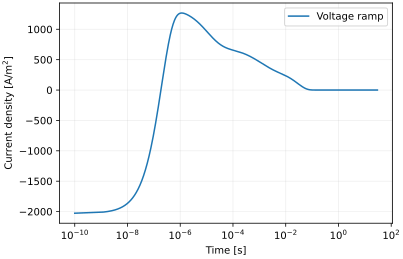

In [50]:
# V(t) = initial + (final - initial) * (1 - exp(-(t - start) / tau)).
ramp = voltage_ramp(
    initial=voltage_before,  # Pre-ramp voltage [V].
    final=ocv,               # Asymptotic target voltage [V].
    tau=2e-7,                # Exponential ramp time constant [s].
    start=0.0,               # Ramp start time [s].
)

# Log-spaced output captures rapid and slow relaxation over 30 s.
t_end = 30.0                              # Simulation end time [s].
times = np.r_[0.0, np.geomspace(1e-9, t_end, 600)]  # Requested output times [s].

ramp_solution = solve_transient(
    model, ramp, (0.0, t_end), initial_state=steady.x,
    t_eval=times, rtol=1e-6, atol=1e-8,  # Solver relative/absolute tolerances.
)

ramp_case = {"Voltage ramp": (model, ramp_solution, ramp)}
ramp_plot = plot_transient(ramp_case, output / "voltage_ramp_current.svg", quantity="current")
display(SVG(filename=str(ramp_plot)))

## 5. Current-interrupt

Interrupt the **mean** current density at `t = 1 s`.

Instantaneous voltage change: -0.0301292 V


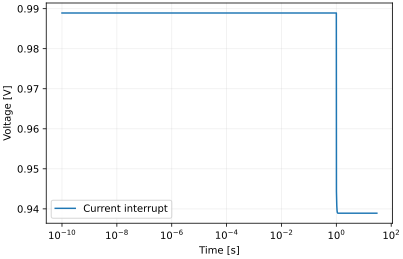

In [51]:
interrupt_at = 1.0  # Interruption time [s]; use 0.0 for an immediate interruption.
interrupt = current_interrupt(current_before=current_before, at=interrupt_at)

# Resolve the fast response relative to interruption, rather than simulation start.
interrupt_times = np.unique(np.r_[
    times[times < interrupt_at], np.nextafter(interrupt_at, -np.inf), interrupt_at,
    interrupt_at + np.geomspace(1e-9, t_end - interrupt_at, 600),
])
interrupt_times = interrupt_times[interrupt_times >= 0.0]
interrupt_solution = solve_transient(
    model, interrupt, (0.0, t_end), initial_state=steady.x,
    t_eval=interrupt_times, rtol=1e-6, atol=1e-8,
)

# At interruption the state is continuous, but terminal voltage changes instantly.
interrupt_index = np.searchsorted(interrupt_solution.t, interrupt_at)
voltage_after = model.voltage_for_current(interrupt_solution.y[:, interrupt_index], 0.0)
print(f"Instantaneous voltage change: {voltage_after - voltage_before:+.6g} V")

interrupt_case = {"Current interrupt": (model, interrupt_solution, interrupt)}
interrupt_plot = plot_transient(
    interrupt_case, output / "current_interrupt_voltage.svg", quantity="voltage"
)
display(SVG(filename=str(interrupt_plot)))

## 6. EIS

Area-specific impedance.

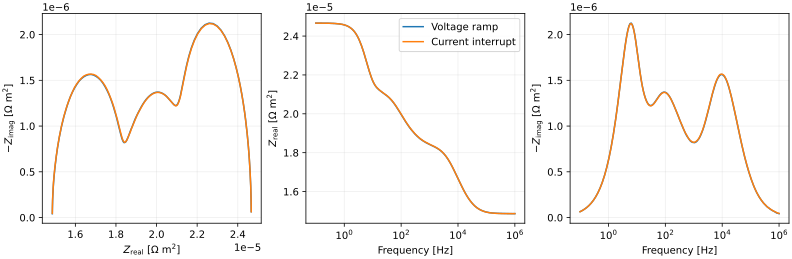

In [52]:
# Frequencies [Hz]; choose a range consistent with record duration and early-time resolution.
frequencies = np.geomspace(0.1, 1e6, 180)

# Voltage control: voltage is imposed; current is calculated from the state.
ramp_voltage = np.array([ramp(t) for t in ramp_solution.t])  # [V].
ramp_current = np.array([
    model.current_density(state, v).mean()
    for state, v in zip(ramp_solution.y.T, ramp_voltage)
])  # [A/m²].

# Current control: mean current is imposed; terminal voltage is calculated.
interrupt_current = np.array([interrupt(t) for t in interrupt_solution.t])  # [A/m²].
interrupt_voltage = np.array([
    model.voltage_for_current(state, j)
    for state, j in zip(interrupt_solution.y.T, interrupt_current)
])  # [V].

# Z(f) = -Fourier[dV/dt] / Fourier[dJ/dt], in area-specific ohm·m².
Z_ramp = impedance(
    ramp_solution.t, ramp_voltage, ramp_current, frequencies,
    voltage_before=voltage_before, current_before=current_before,
)
# Use time since interruption; before values retain the instantaneous response.
record = interrupt_solution.t >= interrupt_at
Z_interrupt = impedance(
    interrupt_solution.t[record] - interrupt_at,
    interrupt_voltage[record], interrupt_current[record], frequencies,
    voltage_before=voltage_before, current_before=current_before,
)

spectra = {
    "Voltage ramp": (frequencies, Z_ramp),
    "Current interrupt": (frequencies, Z_interrupt),
}

impedance_plot = plot_impedance(spectra, output / "impedance.svg")
display(SVG(filename=str(impedance_plot)))

### 6.1. Save impedance data

The spectra below contain simulations only—no experimental data. Check mesh, tolerances, time resolution, and relaxation duration before interpreting the results.

In [53]:
# One CSV contains the two spectra: frequency, Re(Z), and -Im(Z).
impedance_table = np.column_stack((
    frequencies, Z_ramp.real, -Z_ramp.imag, Z_interrupt.real, -Z_interrupt.imag
))
np.savetxt(
    output / "impedance.csv", impedance_table, delimiter=",",
    header="frequency_Hz,ramp_real_ohm_m2,ramp_minus_imag_ohm_m2,interrupt_real_ohm_m2,interrupt_minus_imag_ohm_m2",
    comments="",
)
print("Results saved in:", output)

Results saved in: c:\Users\User\OneDrive - Danmarks Tekniske Universitet\Projects_PostDoc\Flexum\EIS\EIS_for_publication\nest-soc-eis\src\nesteis\examples\tutorials\tutorial_results
